In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
layers = keras.layers
from pathlib import Path
from random import randint

DATA_DIR = Path("doodles")
CLASSES_FILE = Path("class_names.txt")

print("TensorFlow version:", tf.__version__)
print("Dataset folder exists:", DATA_DIR.exists())
print("Classes file exists:", CLASSES_FILE.exists())

/Users/mhrzn_r/Desktop/Nitika/projectIII/paint-kit/doodle-classifier/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow version: 2.15.1
Dataset folder exists: True
Classes file exists: True


In [2]:
with open(CLASSES_FILE, "r") as file:
    class_names = [line.strip() for line in file if line.strip()]

num_classes = len(class_names)

print("Total classes:", num_classes)
print(class_names)

Total classes: 70
['Airplane', 'Angel', 'Ant', 'Apple', 'Axe', 'Banana', 'Bee', 'Bench', 'Bicycle', 'Bird', 'Bow Tie', 'Broom', 'Butterfly', 'Cactus', 'Cake', 'Campfire', 'Candle', 'Car', 'Carrot', 'Cat', 'Clock', 'Cloud', 'Computer', 'Cup', 'Dumbbell', 'Ear', 'Elephant', 'Eye Glasses', 'Eye', 'Face', 'Fan', 'Fish', 'Flower', 'Grapes', 'Guitar', 'Hat', 'Headphones', 'Hot Air Balloon', 'House Plant', 'House', 'Ice Cream', 'Key', 'Leaf', 'Mountain', 'Mouse', 'Mushroom', 'Octopus', 'Pants', 'Pig', 'Pineapple', 'Pizza', 'Rain', 'Rainbow', 'Scissors', 'Sea Turtle', 'Shark', 'Sheep', 'Snail', 'Snowflake', 'Snowman', 'Sock', 'Star', 'Strawberry', 'Sun', 'T-shirt', 'Table', 'The Eiffel Tower', 'Traffic Light', 'Tree', 'Umbrella']


In [3]:
def load_data(root, class_names, max_items_per_class=4000):

    x_data = []
    y_data = []

    for idx, class_name in enumerate(class_names):

        file_path = Path(root) / f"{class_name}.npy"

        if not file_path.exists():
            raise FileNotFoundError(f"Missing dataset file: {file_path}")

        # Load doodles for this class
        data = np.load(file_path)

        # Select maximum number of images
        data = data[:max_items_per_class, :]

        # Check image dimensions
        if data.ndim != 2 or data.shape[1] != 784:
            raise ValueError(
                f"Unexpected shape for {class_name}: {data.shape}"
            )

        # Assign numerical class label
        labels = np.full(data.shape[0], idx)

        x_data.append(data)
        y_data.append(labels)

        print(f"{class_name}: {len(data)} images loaded")

    # Combine all classes
    x = np.concatenate(x_data, axis=0)
    y = np.concatenate(y_data, axis=0)

    # Shuffle dataset
    permutation = np.random.permutation(len(y))

    x = x[permutation]
    y = y[permutation]

    # Split training and testing data (80/20)
    split_index = int(len(x) * 0.8)

    x_train = x[:split_index]
    y_train = y[:split_index]

    x_test = x[split_index:]
    y_test = y[split_index:]

    return x_train, y_train, x_test, y_test

In [4]:
max_items_per_class = 4000

x_train, y_train, x_test, y_test = load_data(
    DATA_DIR,
    class_names,
    max_items_per_class
)

image_size = 28

print("\nDataset loaded successfully!")

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Number of classes:", num_classes)

Airplane: 4000 images loaded
Angel: 4000 images loaded
Ant: 4000 images loaded
Apple: 4000 images loaded
Axe: 4000 images loaded
Banana: 4000 images loaded
Bee: 4000 images loaded
Bench: 4000 images loaded
Bicycle: 4000 images loaded
Bird: 4000 images loaded
Bow Tie: 4000 images loaded
Broom: 4000 images loaded
Butterfly: 4000 images loaded
Cactus: 4000 images loaded
Cake: 4000 images loaded
Campfire: 4000 images loaded
Candle: 4000 images loaded
Car: 4000 images loaded
Carrot: 4000 images loaded
Cat: 4000 images loaded
Clock: 4000 images loaded
Cloud: 4000 images loaded
Computer: 4000 images loaded
Cup: 4000 images loaded
Dumbbell: 4000 images loaded
Ear: 4000 images loaded
Elephant: 4000 images loaded
Eye Glasses: 4000 images loaded
Eye: 4000 images loaded
Face: 4000 images loaded
Fan: 4000 images loaded
Fish: 4000 images loaded
Flower: 4000 images loaded
Grapes: 4000 images loaded
Guitar: 4000 images loaded
Hat: 4000 images loaded
Headphones: 4000 images loaded
Hot Air Balloon: 4000

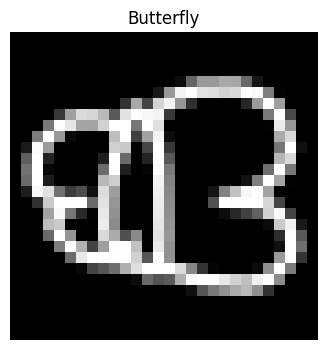

Class label: 12
Class name: Butterfly


In [5]:
idx = randint(0, len(x_train) - 1)

plt.figure(figsize=(4, 4))
plt.imshow(x_train[idx].reshape(28, 28), cmap="gray")
plt.title(class_names[int(y_train[idx])])
plt.axis("off")
plt.show()

print("Class label:", y_train[idx])
print("Class name:", class_names[int(y_train[idx])])

In [6]:
x_train = x_train.reshape(
    x_train.shape[0], image_size, image_size, 1
).astype("float32")

x_test = x_test.reshape(
    x_test.shape[0], image_size, image_size, 1
).astype("float32")

x_train /= 255.0
x_test /= 255.0

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

print("Pixel range:", x_train.min(), "-", x_train.max())

Training shape: (224000, 28, 28, 1)
Testing shape: (56000, 28, 28, 1)
Pixel range: 0.0 - 1.0


In [7]:
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (224000, 70)
Testing labels shape: (56000, 70)


In [8]:
model = keras.Sequential([

    layers.Conv2D(
        16, (3, 3),
        padding="same",
        input_shape=x_train.shape[1:],
        activation="relu"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer=keras.optimizers.Adam(),
    metrics=[
        "accuracy",
        "top_k_categorical_accuracy"
    ]
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 16)        160       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 16)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 32)        4640      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 32)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 7, 7, 64)          18496     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 3, 3, 64)          0

In [9]:
history = model.fit(
    x=x_train,
    y=y_train,
    validation_split=0.1,
    batch_size=256,
    verbose=2,
    epochs=15
)

Epoch 1/15
788/788 - 18s - loss: 1.7678 - accuracy: 0.5596 - top_k_categorical_accuracy: 0.7954 - val_loss: 1.1874 - val_accuracy: 0.6981 - val_top_k_categorical_accuracy: 0.8935 - 18s/epoch - 23ms/step
Epoch 2/15
788/788 - 18s - loss: 1.0392 - accuracy: 0.7381 - top_k_categorical_accuracy: 0.9120 - val_loss: 0.9634 - val_accuracy: 0.7580 - val_top_k_categorical_accuracy: 0.9192 - 18s/epoch - 23ms/step
Epoch 3/15
788/788 - 19s - loss: 0.8768 - accuracy: 0.7793 - top_k_categorical_accuracy: 0.9281 - val_loss: 0.8601 - val_accuracy: 0.7800 - val_top_k_categorical_accuracy: 0.9287 - 19s/epoch - 25ms/step
Epoch 4/15
788/788 - 20s - loss: 0.7879 - accuracy: 0.8005 - top_k_categorical_accuracy: 0.9367 - val_loss: 0.8019 - val_accuracy: 0.7952 - val_top_k_categorical_accuracy: 0.9350 - 20s/epoch - 26ms/step
Epoch 5/15
788/788 - 22s - loss: 0.7271 - accuracy: 0.8154 - top_k_categorical_accuracy: 0.9426 - val_loss: 0.7630 - val_accuracy: 0.8060 - val_top_k_categorical_accuracy: 0.9377 - 22s/epo

In [10]:
score = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", score[0])
print("Test Accuracy: {:.2f}%".format(score[1] * 100))
print("Top-5 Accuracy: {:.2f}%".format(score[2] * 100))

Test Loss: 0.6658087968826294
Test Accuracy: 83.13%
Top-5 Accuracy: 94.78%


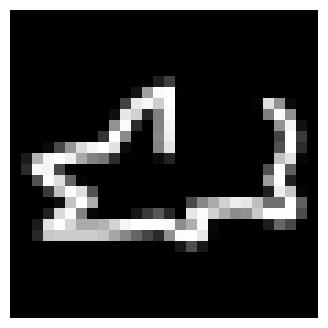

Shark: 99.67%
Car: 0.10%
Octopus: 0.09%
Airplane: 0.04%
Fish: 0.03%


In [11]:
idx = randint(0, len(x_test) - 1)

img = x_test[idx]

plt.figure(figsize=(4, 4))
plt.imshow(img.squeeze(), cmap="gray")
plt.axis("off")
plt.show()

pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]

# Get top 5 predictions
ind = np.argsort(pred)[::-1][:5]

for i in ind:
    print(
        f"{class_names[i]}: {pred[i] * 100:.2f}%"
    )

In [12]:
model.save("doodle_classifier.keras")

with open("class_names.txt", "w") as file:
    for item in class_names:
        file.write(item + "\n")

print("Model and class names saved successfully!")

Model and class names saved successfully!
